In [3]:
# Only needs to be run once to download the data, unless you are working on Google Colab
# uncomment below to download (For UNIX systems)

!curl https://archive.ics.uci.edu/ml/machine-learning-databases/00482/dataset.zip --create-dirs -o  ./data/dataset.zip
!unzip -o ./data/dataset.zip -d ./data/


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100  234k    0  234k    0     0  77913      0 --:--:--  0:00:03 --:--:-- 77919
Archive:  ./data/dataset.zip
  inflating: ./data//dataset.csv     


In [4]:
# To download the py script
!curl https://raw.githubusercontent.com/JonSolow/Parking_TimeSeries/master/Workbook_Init.py >> Workbook_Init.py

# Import libraries and custom functions defined in Workbook_Init.py
from Workbook_Init import *


  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
100 11754  100 11754    0     0  20413      0 --:--:-- --:--:-- --:--:-- 20406


In [5]:
df_raw = pd.read_csv('./data/dataset.csv')

Columns: Index(['systemcodenumber', 'capacity', 'occupancy', 'lastupdated'], dtype='object')


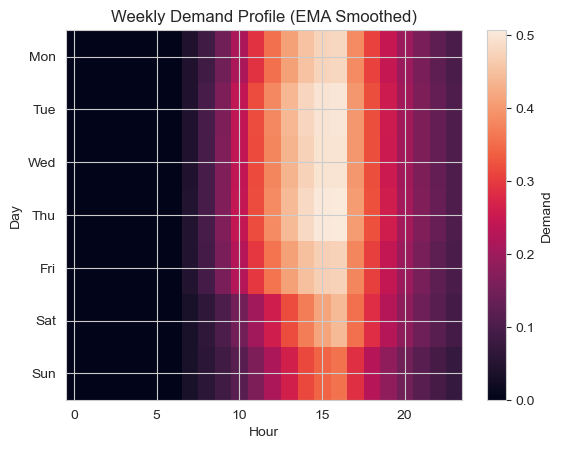

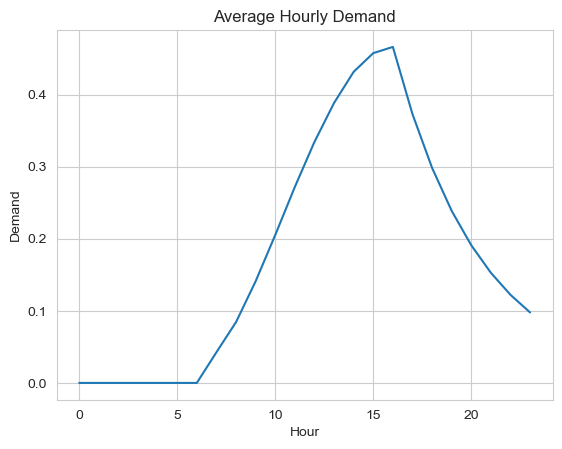

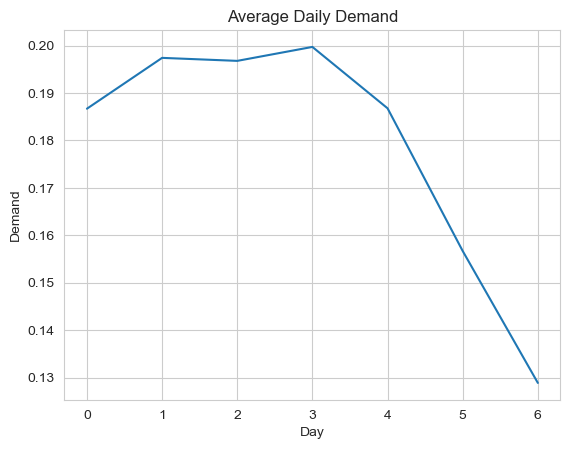

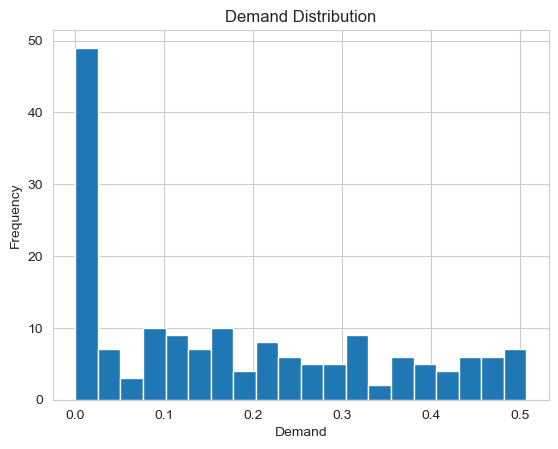

In [12]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = df_raw.copy()

df.columns = [c.lower() for c in df.columns]

print("Columns:", df.columns)

time_col = "lastupdated"
occ_col  = "occupancy"
cap_col  = "capacity"

# convert timestamp
df[time_col] = pd.to_datetime(df[time_col])

# create demand signal (0-1) - demand = occupancy/capacity - normalized to [0,1]
df["demand"] = df[occ_col] / df[cap_col]
df["demand"] = df["demand"].clip(0, 1)


# extract day and hour
df["day"]  = df[time_col].dt.dayofweek   # 0–6
df["hour"] = df[time_col].dt.hour        # 0–23

# build weekly demand profile (7x24)
weekly_matrix = (
    df.groupby(["day", "hour"])["demand"]
      .mean()
      .unstack(fill_value=0)
)

# ensure full shape
weekly_matrix = weekly_matrix.reindex(
    index=range(7),
    columns=range(24),
    fill_value=0
)

D_raw = weekly_matrix.values


# apply EMA smoothing
alpha = 0.2
D_ema = np.zeros_like(D_raw)

for d in range(7):
    for h in range(24):
        if h == 0:
            D_ema[d, h] = D_raw[d, h]
        else:
            D_ema[d, h] = alpha * D_raw[d, h] + (1 - alpha) * D_ema[d, h-1]

# heatmap
plt.figure()
plt.imshow(D_ema, aspect="auto")
plt.colorbar(label="Demand")
plt.xlabel("Hour")
plt.ylabel("Day")
plt.title("Weekly Demand Profile (EMA Smoothed)")
days = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
plt.yticks(range(7), days)

plt.show()

# average hourly demand line plot 
plt.figure()
plt.plot(D_ema.mean(axis=0))
plt.title("Average Hourly Demand")
plt.xlabel("Hour")
plt.ylabel("Demand")
plt.grid(True)
plt.show()

# average daily demand line plot 
plt.figure()
plt.plot(D_ema.mean(axis=1))
plt.title("Average Daily Demand")
plt.xlabel("Day")
plt.ylabel("Demand")
plt.grid(True)
plt.show()

# demand distribution histogram 
plt.figure()
plt.hist(D_ema.flatten(), bins=20)
plt.title("Demand Distribution")
plt.xlabel("Demand")
plt.ylabel("Frequency")
plt.show()
